<a href="https://colab.research.google.com/github/fischdakid/is-4487-labs/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS4487 Week 10 - Assignment

### Outline

Our Goals with this Project:

1. Import and review the data
2. Perform EDA and Clean Data
3. Fit a model
4. Test the accuracy of the model
6.  Use the model to predict on a new dataset (without the target)

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Business Context AdviseInvest
You work on a small team of data analysts at AdviseInvest, a venture-backed startup. The Director of Sales at AdviseInvest has approached your team asking for help solving a staffing problem.

### The Company
The company's mission is to provide tools and support to help ordinary people gain control of their personal finances. The company leverages technology to provide affordable financial advice to a national client base.

Customers who reach AdviseInvest's website go through five steps:

- Open an account.
- Complete a customer profile form with basic information about their background and finances.
- Schedule a free phone conversation with a sales representative during a 1-hour window of time.
- Attend the free phone conversation.
- Buy a financial plan.
- There are three types of financial plans: Beginner, Intermediate, and Advanced. Each is sold at a different price, and there are varying degrees of personalization. After a customer purchases a financial plan, the customer is assigned a financial planner who helps determine the customer's goals and advises the customer on spending decisions.

### The Problem
Some customers are lost at each stage of the process. Steps 3 and 4 are particularly challenging because approximately 50% of those who schedule a phone conversation fail to pick up the call. This leads to inefficiencies from a staffing perspective.

AdviseInvest has 4 sales reps on staff during each particular 1-hour window. Each of the 4 reps is assigned 2 prospective customers per hour, which means that the company schedules a total of 8 phone calls per hour. The calls are outgoing: sales reps call customers who scheduled a phone conversation during that hour window.

Unfortunately, as noted above, many of the customers who scheduled a call do not answer. As a consequence, sales reps are often left underutilized. Moreover, they are underutilized unevenly. For example, it is possible that one sales rep will not do any sales calls during that hour, whereas another will be busy the entire hour with two calls. Sales reps have nothing to do when customers do not answer the scheduled phone call.

### AdviseInvest Data Dictionary


| Variable | Description | Type | Code |
|:---|:---|:---|:---|
| customer_id | Unique customer identifier | Numeric | |
| Answered | Customer response | Binary | 0: customer did not answer scheduled call; 1: customer answered scheduled call |
| Income | Customer income in US dollars | Numeric | |
| Female | Customer gender | Binary | 0: male; 1: female |
| Age | Age in years | Numeric | |
| Job | Nature of job | Categorical | 0 : unemployed; 1 : entry level position; 2 : midlevel position; 3 : management/ self-employed/ highly qualified employee/ officer |
| Num_dependents | Number of people for whom the customer provides maintenance | Numeric | |
| Rent | Customer rents | Binary | 0: no; 1: yes |
| Own_res | Customer owns residence | Binary | 0: no; 1: yes |
| New_car | Recent new car purchase | Binary | New car purchase in the last 3 months: 0: no, 1: yes |
| Chk_acct | Checking account status | Categorical | 0 : no checking account; 1: checking < 200 USD; 2 : 200 < checking < 2000 USD; 3: 2000 < checking < 35000 USD; 4: >= 3500 USD |
| Sav_acct | Average balance in savings account | Categorical | 0 : no savings account; 1 : 100 <= savings < 500 USD; 2 : 500 <= savings < 2000 USD; 3 : 2000 < savings < 35000 USD; 4: >= 3500 USD |
| Num_accts | Number of accounts owned by customer | Numeric | |
| Mobile | Mobile phone | Binary | 0: customer provided non‐mobile phone for follow‐up call; 1: customer provided mobile phone for follow‐up call |
| Product | Type of product purchased after conversation with sales rep | Categorical | 0: customer did not answer call; 1: customer answered but did not purchase a product; 2: customer answered and purchased Beginner plan; 3: customer answered and purchased Intermediate plan; 4: customer answered and purchased Advanced plan |

### Load Libraries

Import the libraries you will need, such as:
- Pandas
- Sklearn
- Matplotlib


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix

## Step 1: Initial Data Understanding

### Do the following:
 - Import data from the AdviseInvest historical dataset into a dataframe (in GitHub go to the DataSets folder and look for `adviseinvest_historical_data.csv`).  The GitHub page is https://github.com/Stan-Pugsley/is_4487_base/tree/main/DataSets
 - Describe or profile the dataframe
 - Look for any outliers, missing values, or duplicates

(29504, 15)
   customer_id  answered  income female  age  job  num_dependents  rent  \
0        10098         0  -65600      0   24    2               1     0   
1          184         0    4330      0   24    2               2     1   
2          194         0    4330      0   22    2               1     1   
3          689         0    4330      0   24    2               2     1   
4          811         0    4330      0   22    2               1     1   

   own_res  new_car  chk_acct  sav_acct  num_accts  mobile  product  
0        1      1.0         1         1          3       0        0  
1        0      0.0         1         3          1       0        0  
2        0      0.0         3         0          0       0        0  
3        0      0.0         1         3          1       0        0  
4        0      0.0         3         0          0       0        0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29504 entries, 0 to 29503
Data columns (total 15 columns):
 #   Col

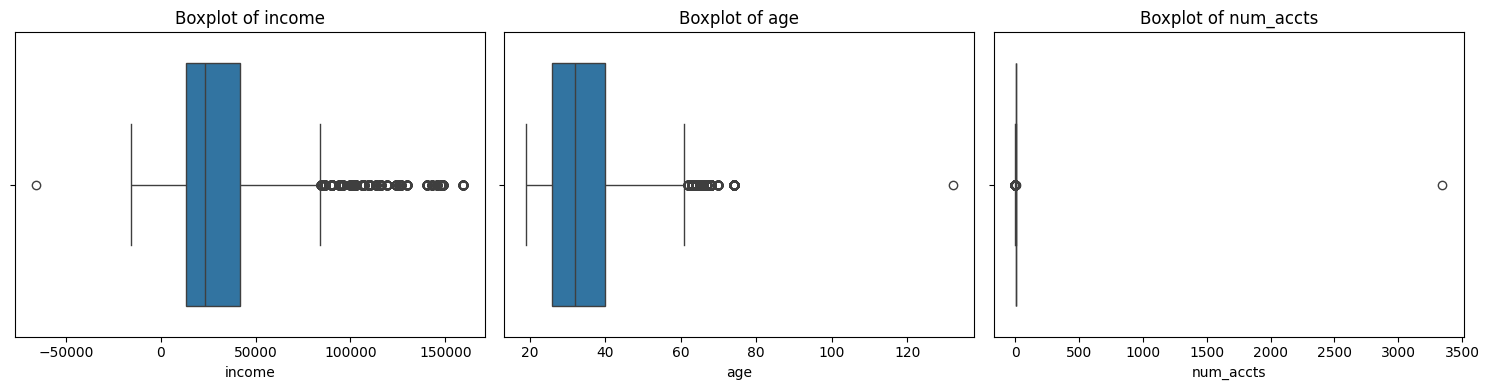

In [2]:
url = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/adviseinvest_historical_data.csv"
df = pd.read_csv(url)

print(df.shape)
print(df.head())
print(df.info())
print(df.describe().T)

# Missing values, duplicates, and odd values
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate customer_ids:", df["customer_id"].duplicated().sum())
print("\nUnique values in female:", df["female"].unique())
print("\nNegative income rows:", (df["income"] < 0).sum())
print("Age > 100 rows:", (df["age"] > 100).sum())
print("num_accts value counts:\n", df["num_accts"].value_counts().sort_index())

# Boxplots to spot outliers in the numeric columns
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["income", "age", "num_accts"]):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(f"Boxplot of {col}")
plt.tight_layout()
plt.show()

### Reflection:
1.1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1.1. The things that stand out to me during the initial preview of the dataset are the impossible values like customers with negative incomes, wrong data types, missing values, duplicates, and the product column. There are many unsual findings in here.

# Step 2: Data Preparation

## 2.1: Data Cleanup

### Do the following:
- 2.1 Check for and remove any outliers
- 2.2 Consider fixing any missing data (should you delete the record or impute the value?)
- 2.3 remove any variables, like customer_id, that are not helpful in predicting the target variable (hint: are there any variables that are available only AFTER the customer has answered, and wouldn't be useful in predicting?)
- 2.4 Clean up the data and put it in a new dataframe named "df_clean"


In [3]:
df_clean = df.copy()

# 2.1 Remove outliers / impossible values
df_clean = df_clean[df_clean["income"] >= 0]          # negative income
df_clean = df_clean[df_clean["age"] <= 100]           # age of 132
df_clean = df_clean[df_clean["num_accts"] <= 4]       # 8 and 3345 accounts (normal range is 0-4)
df_clean = df_clean[df_clean["female"].isin(["0", "1", 0, 1])]  # bad "M" value in female

# 2.2 Missing data - only 2 rows missing new_car, so drop them
df_clean = df_clean.dropna()

# Duplicates
df_clean = df_clean.drop_duplicates()

# 2.3 Drop columns that don't help predict answered
# customer_id is just an ID; product is only known AFTER the customer answers (data leakage)
df_clean = df_clean.drop(columns=["customer_id", "product"])

print("Rows before:", len(df), " Rows after:", len(df_clean))
print(df_clean.isna().sum().sum(), "missing values remaining")
df_clean.head()

Rows before: 29504  Rows after: 29493
0 missing values remaining


,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile
1,0,4330,0,24,2,2,1,0,0.0,1,3,1,0
2,0,4330,0,22,2,1,1,0,0.0,3,0,0,0
3,0,4330,0,24,2,2,1,0,0.0,1,3,1,0
4,0,4330,0,22,2,1,1,0,0.0,3,0,0,0
6,0,4330,0,22,2,1,1,0,0.0,3,0,0,0


### Reflection:
2.5  Explain the steps that you took to clean outliers and missing data.  Why did you chose the approach that you used?

2.6  Which variables did you remove, and why?

### ✍️ Your Response: 🔧
2.5 I started by deleting the bad rows instead of fixing them. I removed the customers with negative income, the one with the age of 132, and the Male in the female column since they must be errors. Since its only 11 rows out of 29504 it seemed fine to go ahead and delete.

2.6 I removed the varible customer ID becaise it's just and ID number with not predictive meaning. I also went ahead and removed the product variable since its only known if a customer answers the call, so it isn't helpful with predicting who to call. Since it matches answered keeping it would cause data leakage.

## 2.2: Standardize variables

### Do the following:
 - Change "answered" to a boolean (true/false) type
 - Convert any variables that should be an integer into an integer

In [4]:
df_clean["answered"] = df_clean["answered"].astype(bool)

int_cols = ["income", "female", "age", "job", "num_dependents", "rent", "own_res",
            "new_car", "chk_acct", "sav_acct", "num_accts", "mobile"]
df_clean[int_cols] = df_clean[int_cols].astype(int)

df_clean.dtypes

,0
answered,bool
income,int64
female,int64
age,int64
job,int64
num_dependents,int64
rent,int64
own_res,int64
new_car,int64
chk_acct,int64


## 2.3 Convert variables

### Do the following:
- convert at least 3 variables to categorical where that data type is appropriate

In [5]:
cat_cols = ["job", "chk_acct", "sav_acct", "female", "rent", "own_res", "new_car", "mobile"]
for col in cat_cols:
    df_clean[col] = df_clean[col].astype("category")

df_clean.dtypes

,0
answered,bool
income,int64
female,category
age,int64
job,category
num_dependents,int64
rent,category
own_res,category
new_car,category
chk_acct,category


# Step 3: Exploratory Data Analysis (EDA)

### Do the following:
- Explore the relationships between the target and independent variables
- Create at least five charts to show the relationships, using different chart types that are approriate to the analysis
- Ensure that all charts are clearly labeled and formatted



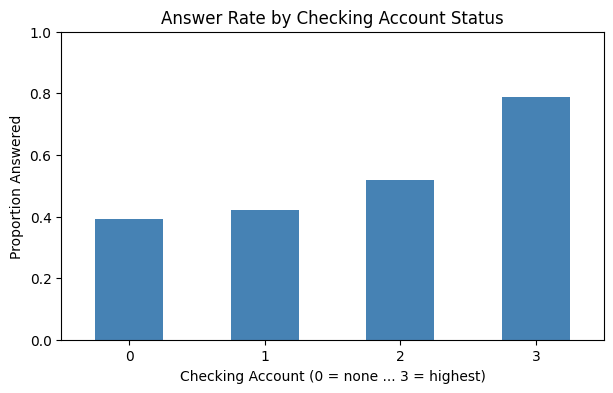

In [6]:
# Chart 3.1 - Answer rate by checking account status (bar chart)
rate = df_clean.groupby("chk_acct", observed=True)["answered"].mean()
rate.plot(kind="bar", color="steelblue", figsize=(7, 4))
plt.title("Answer Rate by Checking Account Status")
plt.xlabel("Checking Account (0 = none ... 3 = highest)")
plt.ylabel("Proportion Answered")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.show()

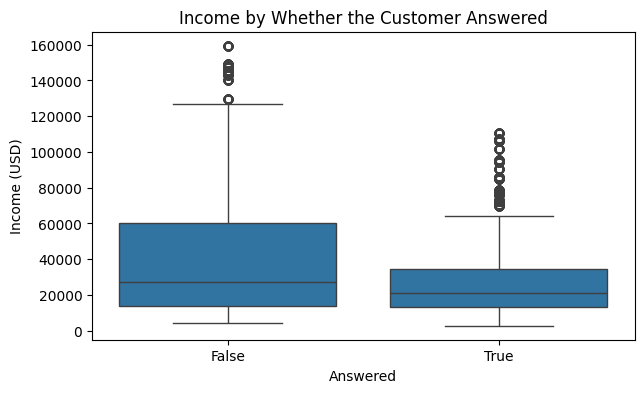

In [7]:
# Chart 3.2 - Income distribution by answered (boxplot)
plt.figure(figsize=(7, 4))
sns.boxplot(data=df_clean, x="answered", y="income")
plt.title("Income by Whether the Customer Answered")
plt.xlabel("Answered")
plt.ylabel("Income (USD)")
plt.show()

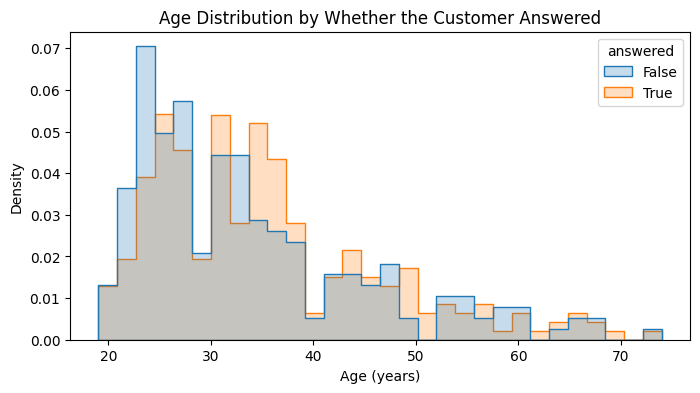

In [8]:
# Chart 3.3 - Age distribution by answered (overlapping histogram)
plt.figure(figsize=(8, 4))
sns.histplot(data=df_clean, x="age", hue="answered", bins=30, element="step", stat="density", common_norm=False)
plt.title("Age Distribution by Whether the Customer Answered")
plt.xlabel("Age (years)")
plt.ylabel("Density")
plt.show()

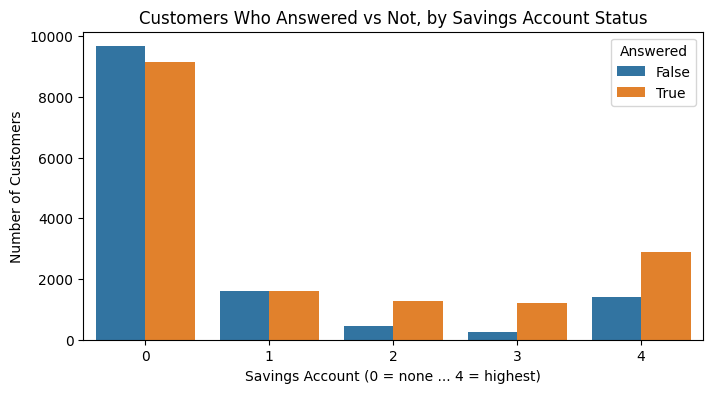

In [9]:
# Chart 3.4 - Answered counts by savings account status (grouped count plot)
plt.figure(figsize=(8, 4))
sns.countplot(data=df_clean, x="sav_acct", hue="answered")
plt.title("Customers Who Answered vs Not, by Savings Account Status")
plt.xlabel("Savings Account (0 = none ... 4 = highest)")
plt.ylabel("Number of Customers")
plt.legend(title="Answered")
plt.show()

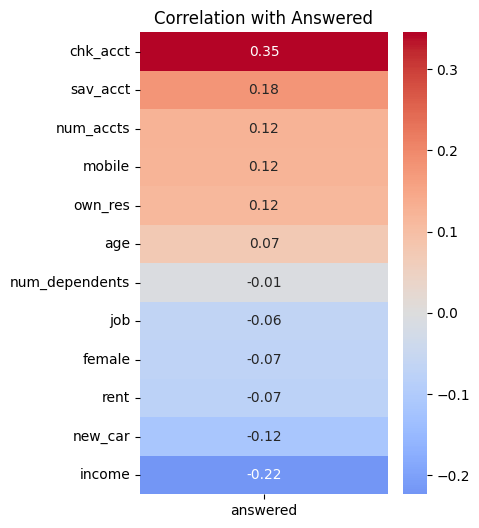

In [10]:
# Chart 3.5 - Correlation of each variable with answered (heatmap)
corr = df_clean.astype(float).corr()[["answered"]].drop("answered").sort_values("answered", ascending=False)
plt.figure(figsize=(4, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation with Answered")
plt.show()

### Reflection:
3.6. Which variables show the strongest relationship with the target variable?

3.7. Did you find any variables that have a weak relationship with the target variable?  Should they be removed?

### ✍️ Your Response: 🔧
3.6. The strongest variable for showing relationship with the target variable is checking account status. Next is the income, followed by saving account status, and having a mobile phone.

3.7. Yes I did, number of dependents is close to zero along with age, job, and gender. I ended up keeping them becausr the decision tree can find nonlinear patterns and will simply ignore varibale that aren't helpful.

## Step 4: Modeling

Start with the baseline.  If we use no model at all, how good is our chance of predicting someone leaving?  Use a calculation to find the chances of someone leaving.

### Do the following:
4.1 Calculate the base probability of answering  

In [11]:
base_prob = df_clean["answered"].mean()
print(f"Base probability of answering: {base_prob:.4f}")
print(f"Base accuracy (always predict the majority class): {max(base_prob, 1 - base_prob):.4f}")

Base probability of answering: 0.5467
Base accuracy (always predict the majority class): 0.5467


## 4.2: Split the training and testing datasets

### Do the following:
- split df_clean using train_test_split function

Notes:
- all remaining variables except answered should be in the x variable
- answered is in the y variable


In [12]:
X = df_clean.drop(columns=["answered"])
y = df_clean["answered"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print(X_train.shape, X_test.shape)

(20645, 12) (8848, 12)


## 4.3: Create a Decision Tree

### Do the following:
- Create a tree
- Display (visualize) the tree

Notes:
- Use all available attributes (except those that were eliminated in step 3)
- It is recommended to use the type "entropy" and a max_depth of 4

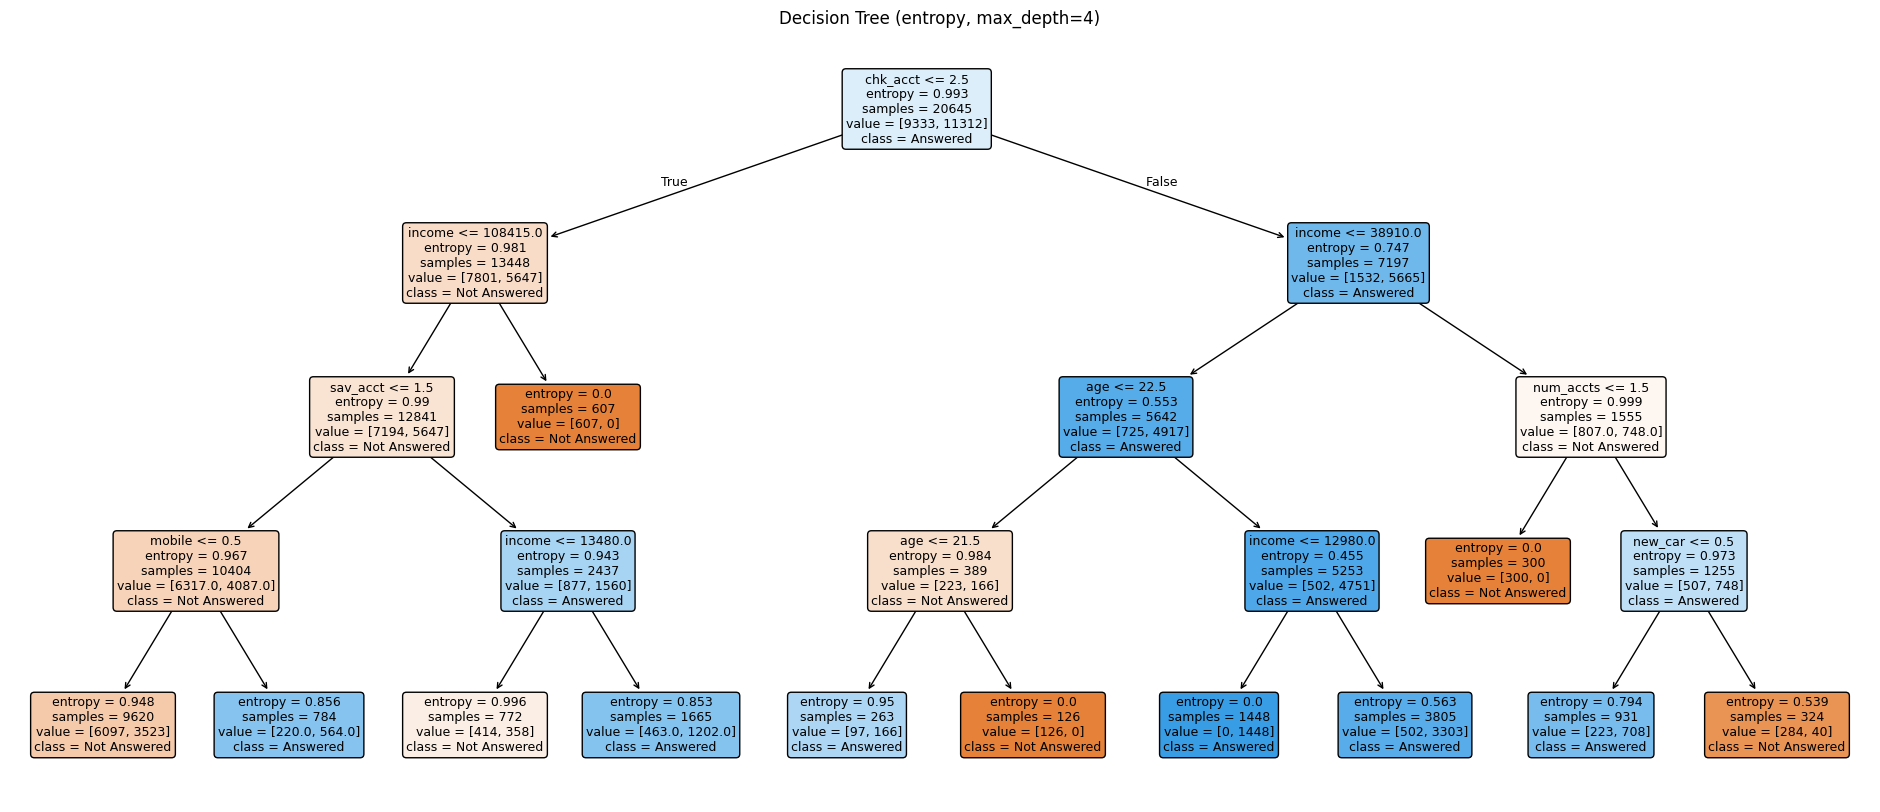

In [13]:
tree = DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=42)
tree.fit(X_train, y_train)

plt.figure(figsize=(24, 10))
plot_tree(tree, feature_names=X.columns, class_names=["Not Answered", "Answered"],
          filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree (entropy, max_depth=4)")
plt.show()

## 4.4: Calculate the accuracy

This should be better than the base probability, or you have failed in your objective

### Do the following:
- Calculate the probability for your tree

In [14]:
y_pred = tree.predict(X_test)
tree_acc = accuracy_score(y_test, y_pred)
print(f"Tree accuracy: {tree_acc:.4f}")
print(f"Base accuracy: {max(base_prob, 1 - base_prob):.4f}")
print(f"Improvement:   {tree_acc - max(base_prob, 1 - base_prob):.4f}")

Tree accuracy: 0.7453
Base accuracy: 0.5467
Improvement:   0.1986


### Reflection:
1. What is the difference between the probability from the model compared to the base probability?
2. Is this difference a significant amount for the business?  

### ✍️ Your Response: 🔧
1. The decision tree is 75.5% accurate, comparted to the 54.75 baseline. That is an improvement of accuracy which means the model is predicting better than just guessing common outcomes.

2. Yes it is, having better prediction accuracy is beneficial to sales reps so they can skip calls that won't get answered but the model still misses about 1650 customers who would have answered.


### 4.5: Confusion Matrix

### Do the following
- Create a confusion matrix

This will show false positives, true positives, etc.

In [15]:
cm = confusion_matrix(y_test, y_pred)
print(cm)
tn, fp, fn, tp = cm.ravel()
print(f"TN: {tn}  FP: {fp}  FN: {fn}  TP: {tp}")

[[3430  607]
 [1647 3164]]
TN: 3430  FP: 607  FN: 1647  TP: 3164


Create a more visual, interpretable version of the matrix (hint - try using Seaborn Heatmap)

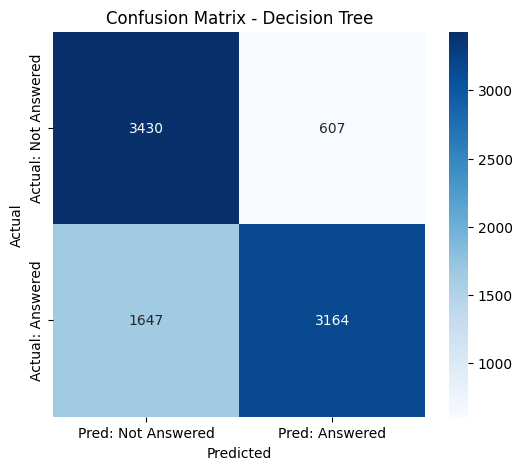

In [16]:
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred: Not Answered", "Pred: Answered"],
            yticklabels=["Actual: Not Answered", "Actual: Answered"])
plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Step 5: Evaluate the Model

**Assumptions**

One of the simplifying assumptions we will make in this project is that all the customers who answer the phone will purchase a product. (This assumption is actually verified by the data.) To model "answered" in this case is therefore equivalent to modeling "purchased."

There are costs and benefits in this case. We will assume that customers purchase a product for 100 dollars. This was the average cost of AdviseInvest products, according to the Director of Sales.  Also, as we learned in the interview, the agent time to make the sale is worth 25 dollars. Profit would therefore be \$75 dollars for an answered call and a purchase. In sum:

**Benefit**: True positive. The customer is predicted to answer, does answer, and purchases a product for 100 dollars for a profit of 100 - 25 = 75.

**Cost**: False positive. The customer is predicted to answer, but does not answer, so there is a loss of 25. (We assume the agent cannot schedule another call at the last minute, or spends the entire time slot trying to make the call.)

When you create a calculation you can use:
- True answered * 75 -> These people purchased
- False answered * 25 -> You can't schedule another call

For this exercise, we propose that customers who are not predicted to answer will not be called, so there would be no benefits and no costs for them.  

### Do the following:
Calculate the Profit Using the Model

In [17]:
# Only customers predicted to answer get called
model_profit = tp * 75 - fp * 25
print(f"True positives: {tp}  False positives: {fp}")
print(f"Profit using the model: ${model_profit:,}")

True positives: 3164  False positives: 607
Profit using the model: $222,125


### 5.2 Compare to the Default Profit

### Do the following:
- Calculate the profit (revenue - costs) that would be expected if all customers are called

Notes:
- We can consider this a baseline case for profit since it does not require a model
- In other words, to calculate profit in this baseline scenario treat the customers who answer as true positives treat the customers who do not answer as false positives.

In [18]:
# Call everyone in the test set: answered = TP, didn't answer = FP
all_answered = y_test.sum()
all_not_answered = (~y_test).sum()
default_profit = all_answered * 75 - all_not_answered * 25
print(f"Answered: {all_answered}  Not answered: {all_not_answered}")
print(f"Profit calling everyone: ${default_profit:,}")
print(f"Model profit:            ${model_profit:,}")
print(f"Difference:              ${model_profit - default_profit:,}")

Answered: 4811  Not answered: 4037
Profit calling everyone: $259,900
Model profit:            $222,125
Difference:              $-37,775


### Reflection:
1. What is the difference in profit between calling all customers and calling customers that are recommended by the model?
2. Is this a significant amount for the business?  

### ✍️ Your Response: 🔧
1. If you call every customer it earns about 259900 comaprted to only calling ones the model recommend earns 22125. The model makes slightly less than calling every customer and misses out on about 1650 customers who would've answered.

2. This is about a 15% drop in profit which is significant. This makes me think that this version of the model should not be used. Saving 25 on customers who wouldn't answer doesn't make up for earning 75 on each customer who was missed in sales.


## 5.3 Tune the Model

### Do the Following
- Create a new version of the tree with new parameters
- Calculate a new probability

Notes:
- Adjust the size or shape of the tree, then test the accuracy
- Keep changing these parameters until you end up with a tree with accuracy that is better than the initial model

In [19]:
# Try a range of depths and keep the best one
results = []
for depth in range(2, 16):
    for leaf in [1, 5, 10, 20, 50]:
        m = DecisionTreeClassifier(criterion="entropy", max_depth=depth, min_samples_leaf=leaf, random_state=42)
        m.fit(X_train, y_train)
        results.append((depth, leaf, accuracy_score(y_test, m.predict(X_test))))

results_df = pd.DataFrame(results, columns=["max_depth", "min_samples_leaf", "accuracy"]).sort_values("accuracy", ascending=False)
print(results_df.head(10))

best = results_df.iloc[0]
tree2 = DecisionTreeClassifier(criterion="entropy", max_depth=int(best["max_depth"]),
                               min_samples_leaf=int(best["min_samples_leaf"]), random_state=42)
tree2.fit(X_train, y_train)
y_pred2 = tree2.predict(X_test)
tree2_acc = accuracy_score(y_test, y_pred2)

print(f"\nOriginal tree accuracy: {tree_acc:.4f}")
print(f"Tuned tree accuracy:    {tree2_acc:.4f}  (max_depth={int(best['max_depth'])}, min_samples_leaf={int(best['min_samples_leaf'])})")

tn2, fp2, fn2, tp2 = confusion_matrix(y_test, y_pred2).ravel()
tuned_profit = tp2 * 75 - fp2 * 25
print(f"Tuned model profit:     ${tuned_profit:,}")

    max_depth  min_samples_leaf  accuracy
67         15                10  0.917608
66         15                 5  0.917608
65         15                 1  0.917608
68         15                20  0.917608
61         14                 5  0.912636
60         14                 1  0.912636
63         14                20  0.912636
62         14                10  0.912636
69         15                50  0.881894
56         13                 5  0.880425

Original tree accuracy: 0.7453
Tuned tree accuracy:    0.9176  (max_depth=15, min_samples_leaf=10)
Tuned model profit:     $324,350


### 5.4 Apply the Model to New Customers

### Do the Following
- Import the "adviseinvest_new_customer_data.csv" file
- Copy and past the data cleanup steps from 2.1 and 2.2
- Using the tree model that you created in step 5.3, predict each customer for the target variable by feeding the new customer data into the model
- Predict the number of customers who will be yes/no for the target variable

In [20]:
new_url = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/adviseinvest_new_customer_data.csv"
df_new = pd.read_csv(new_url)

# Same cleanup as 2.1: check for missing values, drop customer_id (no answered/product columns in this file)
print("Missing values:", df_new.isna().sum().sum())
df_new_clean = df_new.drop(columns=["customer_id"])

# Same standardizing / conversion as 2.2 and 2.3
df_new_clean[int_cols] = df_new_clean[int_cols].astype(int)
for col in cat_cols:
    df_new_clean[col] = df_new_clean[col].astype("category")

# Match the training column order
df_new_clean = df_new_clean[X.columns]

# Predict with the tuned tree
df_new["predicted_answer"] = tree2.predict(df_new_clean)

print(df_new["predicted_answer"].value_counts())
print(f"\nPredicted to answer (call these): {df_new['predicted_answer'].sum()}")
print(f"Predicted NOT to answer:          {(~df_new['predicted_answer']).sum()}")
df_new[["customer_id", "predicted_answer"]].head(10)

Missing values: 0
predicted_answer
True     553
False    447
Name: count, dtype: int64

Predicted to answer (call these): 553
Predicted NOT to answer:          447


,customer_id,predicted_answer
0,H1597,True
1,P1446,False
2,E1492,True
3,W5143,False
4,W4927,False
5,M6161,True
6,U4472,False
7,H557,True
8,B54,True
9,L2217,True


# Step 6: Conclusion

### Reflection:
6.1: Did we improve our profit using the model?  

6.2: How could the model be utilized by the business?

### ✍️ Your Response: 🔧
6.1 Yes we did, but by using the tuned tree not the orginal. The original lower profit by 3775 and the finalized tuned tree raised it to 324250 which is about 25% more than calling everyone. The answer is yes, the tuned model improves profit but the orginal model does not.

6.2 AdviseInvest could use the model to score customers when they schedule a call and prioritze customers who are likely to answer. They could also decide to overbook time slots better on the fact that some customers will not answer but giving them a chance to close more. this could keep reps busy, spread out the workload, and help the company with accurate staffing.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [22]:
!jupyter nbconvert --to html "assignment_10_classification.ipynb"

[NbConvertApp] Converting notebook assignment_10_classification.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 8 image(s).
[NbConvertApp] Writing 940707 bytes to assignment_10_classification.html
